# Gaussian EM decay correction ablation

**A02.2 · Sprint 6 · Subteam A · Rishank Goyal**

This notebook checks how decay-corrected gases affect Gaussian EM on matched anchor runs. Mean numeric skill falls from **0.671 to 0.641**, and the ordering relative to MissForest reverses.

**Run this notebook.** Use a Python 3 Jupyter kernel with pandas and Matplotlib, then run all cells. The tables and figures use embedded extracts of the saved benchmark scores. They reproduce the analysis from those scores.

## What changed between arms

The comparison holds the model-only arm, nominal 30% scattered gaps, ±5% measured noise, and the nine generator–split pairs fixed. It compares the saved configurations with and without the decay correction. The reported score is the mean skill across 13 numeric fields, excluding the placebo.

In the Gaussian EM implementation, the enabled correction shifts gas values in the mixture representation and reverses the shift for reported predictions. The paired result measures the net difference between the saved feature configurations.

In [1]:
%matplotlib inline
from io import StringIO
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PAIR = ["generator_seed", "split_seed"]
FIELD = {
    "x": "x", "y": "y", "install_date": "Installation day", "model_id": "Model ID",
    "altitude": "Altitude", "measured_humid": "Humidity", "measured_salt": "Salt",
    "measured_overgrowth": "Overgrowth", "life": "Life", "random_placebo": "Placebo",
    "measured_gas_a": "Gas A", "measured_gas_b": "Gas B", "measured_gas_c": "Gas C",
    "total_gas": "Total gas", "leakage": "Leakage",
}
TEAL, NAVY, RUST, MUTE = "#087973", "#203e53", "#a3452a", "#647783"
plt.rcParams.update({
    "figure.dpi": 140, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY, "axes.axisbelow": True, "grid.alpha": 0.22,
})

In [2]:
CONDITIONS = ["30% scattered", "70% scattered", "30% grouped"]
NAMES = {"mixture": "Gaussian EM", "forest": "MissForest"}

In [3]:
# Archived score extract. Rows and columns are restricted to this analysis.
feature_evidence = pd.read_csv(StringIO("""
method,domain_features,generator_seed,split_seed,macro_skill
forest,False,219,617,0.6642341630541152
forest,False,219,631,0.6608413113918605
forest,False,219,653,0.6762915704986026
forest,False,220,617,0.648656961862767
forest,False,220,631,0.6492004161908569
forest,False,220,653,0.6442835041295262
forest,False,221,617,0.663351161771389
forest,False,221,631,0.657066562078171
forest,False,221,653,0.6468787822696609
mixture,False,219,617,0.6649825131105891
mixture,False,219,631,0.6703647833723299
mixture,False,219,653,0.6825830492599703
mixture,False,220,617,0.6745476133101309
mixture,False,220,631,0.658769395864953
mixture,False,220,653,0.6697157016132493
mixture,False,221,617,0.6770019062579938
mixture,False,221,631,0.6705748097830926
mixture,False,221,653,0.6742750268397197
forest,True,219,617,0.6596825490762511
forest,True,219,631,0.6571734366552107
forest,True,219,653,0.6757834428651043
forest,True,220,617,0.6447390835743599
forest,True,220,631,0.6479006784508734
forest,True,220,653,0.6469302627325839
forest,True,221,617,0.6634616074595393
forest,True,221,631,0.654266810658674
forest,True,221,653,0.6521064775801411
mixture,True,219,617,0.644998559884692
mixture,True,219,631,0.6382115841116982
mixture,True,219,653,0.6510077669600933
mixture,True,220,617,0.6445509206530768
mixture,True,220,631,0.6225757104277669
mixture,True,220,653,0.6403510784764035
mixture,True,221,617,0.6463650339577007
mixture,True,221,631,0.6394036191175773
mixture,True,221,653,0.641803448753457
"""))

In [4]:
paired = feature_evidence.pivot(index=["method", *PAIR], columns="domain_features", values="macro_skill")
paired = paired.rename(columns={False: "Without correction", True: "With correction"})
paired["Change"] = paired["With correction"] - paired["Without correction"]
assert paired.groupby(level="method").size().eq(9).all()
means = paired.groupby(level="method").mean()
em = means.loc["mixture"].round(3)
assert tuple(em) == (0.671, 0.641, -0.030)

## Matched pair differences

In [5]:
display(means.rename(index=NAMES).style.format(precision=4))
display(paired.xs("mixture").style.format(precision=4))
em_pairs = paired.xs("mixture")
forest_pairs = paired.xs("forest")
wins = (em_pairs.iloc[:, :2] > forest_pairs.iloc[:, :2]).sum()
drops = int(em_pairs.Change.lt(0).sum())
assert wins.tolist() == [9, 0] and drops == 9
display(wins.to_frame("Pairs where EM scores above MissForest"))

domain_features,Without correction,With correction,Change
method,,,
MissForest,0.6568,0.6558,-0.0010
Gaussian EM,0.6714,0.6410,-0.0304


,Pairs where EM scores above MissForest
domain_features,
Without correction,9
With correction,0


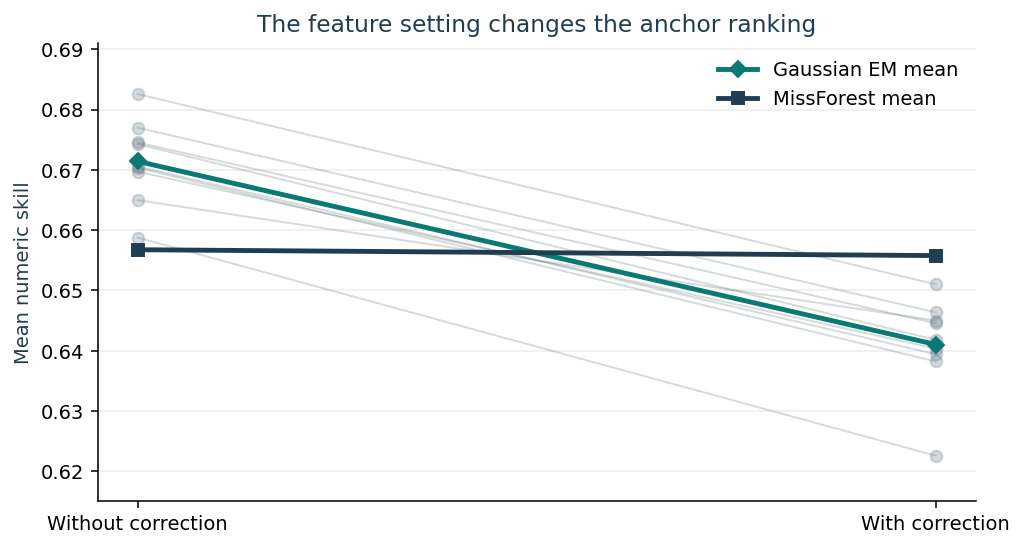

In [6]:
feature_columns = ["Without correction", "With correction"]
fig, ax = plt.subplots(figsize=(7.2, 3.8), layout="constrained")
for _, values in em_pairs[feature_columns].iterrows():
    ax.plot(feature_columns, values, color=MUTE, marker="o", alpha=0.27, linewidth=1)
for method, color, marker in [("mixture", TEAL, "D"), ("forest", NAVY, "s")]:
    ax.plot(feature_columns, means.loc[method, feature_columns],
            color=color, marker=marker, linewidth=2.5, label=f"{NAMES[method]} mean")
ax.set(title="The feature setting changes the anchor ranking",
       ylabel="Mean numeric skill", ylim=(0.615, 0.691))
ax.grid(axis="y")
ax.legend(frameon=False, loc="upper right")
plt.show()

## Interpretation

With decay correction enabled, Gaussian EM has lower skill on all nine matched pairs than in its corresponding disabled run. It leads MissForest on all nine without the correction, and MissForest leads on all nine with it. The average change for MissForest is about −0.001.

The ranking is specific to the feature configuration and the synthetic anchor. The ablation establishes the observed change in skill. The mechanism behind Gaussian EM’s loss remains unresolved.

## Sources and reproducibility

Paths are relative to the original Subteam A run archive. Hash prefixes identify the archived files. The embedded extracts allow the calculations above to run in a fresh notebook session. Use the repository’s setup and benchmark instructions to reproduce the source runs with the Team 19 data.

| Archived source | Evidence used | SHA-256 prefix |
| --- | --- | --- |
| final/tables/macro_run_scores.csv | Model-only anchor pair scores with gas correction on and off | 280b4303444c8d02 |

[Section 10 of the capstone report](https://github.com/alienblack/SAPN_endtoend/blob/6ae6621/docs/Final_Report.pdf) · [Source code and reproduction guide](https://github.com/alienblack/SAPN_endtoend)